# 01 · Data quality and exploratory analysis

**Question:** What does this sample contain, how trustworthy is it, and which patterns deserve follow-up?

Run from the repository root. Place the IBM CSV in `data/raw/` first.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from datapulse.data import load_telco, quality_report
sns.set_theme(style='whitegrid', palette='colorblind')
RANDOM_STATE = 42
DATA_DIR = ROOT / 'data' / 'raw'
candidates = [DATA_DIR / 'Telco-Customer-Churn.csv', DATA_DIR / 'WA_Fn-UseC_-Telco-Customer-Churn.csv']
data_path = next((path for path in candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Download IBM Telco Customer Churn CSV into data/raw/. See data/raw/README.md')
df = load_telco(data_path)
print(f'Loaded {data_path.name}: {df.shape[0]:,} rows × {df.shape[1]} columns')

Loaded Telco-Customer-Churn.csv: 7,043 rows × 21 columns


## Dataset snapshot
The source's customer IDs are identifiers, not predictors. `Churn` is the outcome. `TotalCharges` may contain whitespace in the source; the loader converts it to numeric and treats blanks as missing.

In [2]:
display(df.head())
display(df.describe(include='all').T)
print('Duplicate rows:', int(df.duplicated().sum()))
print('Duplicate customer IDs:', int(df['customerID'].duplicated().sum()) if 'customerID' in df else 'ID absent')
display(quality_report(df))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0
Duplicate customer IDs: 0


,dtype,missing_count,missing_pct,unique_count
TotalCharges,float64,11,0.16,6530
gender,str,0,0.00,2
SeniorCitizen,int64,0,0.00,2
Partner,str,0,0.00,2
Dependents,str,0,0.00,2
PhoneService,str,0,0.00,2
PaperlessBilling,str,0,0.00,2
Churn,str,0,0.00,2
MultipleLines,str,0,0.00,3
InternetService,str,0,0.00,3


## Outcome and numeric feature distributions
Churn is imbalanced, so later evaluation emphasizes precision-recall performance and operating-point trade-offs alongside ROC-AUC.

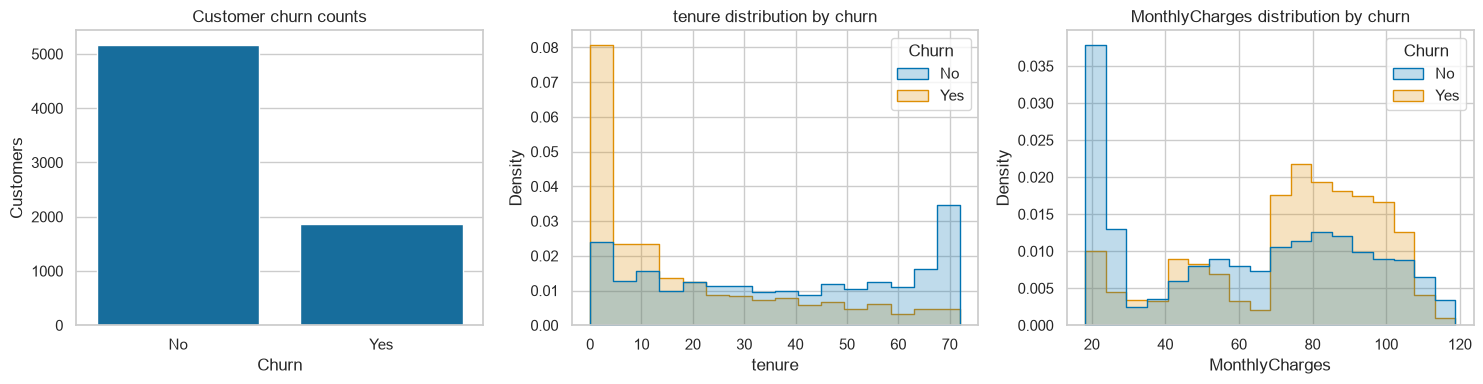

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2555.34  1683.60
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='Churn', ax=axes[0])
axes[0].set_title('Customer churn counts')
axes[0].set_ylabel('Customers')
for axis, col in zip(axes[1:], ['tenure', 'MonthlyCharges']):
    sns.histplot(data=df, x=col, hue='Churn', stat='density', common_norm=False, element='step', ax=axis)
    axis.set_title(f'{col} distribution by churn')
plt.tight_layout(); plt.show()
display(df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(2))

## Categorical churn rates
Rates are descriptive and unadjusted. Small groups can have noisy rates; the statistical notebook adds uncertainty and tests.

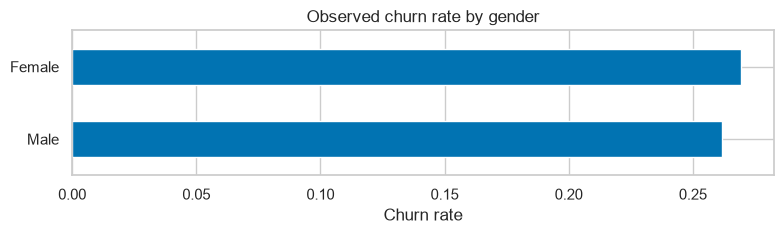

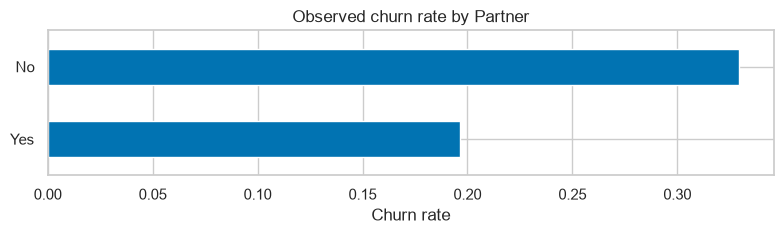

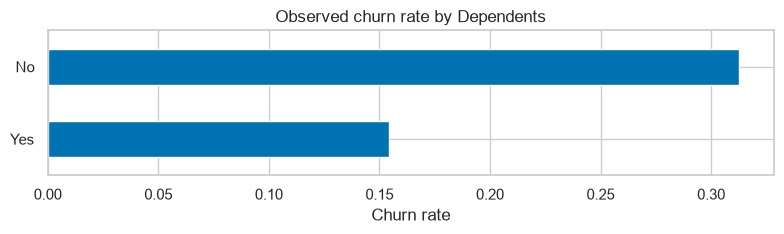

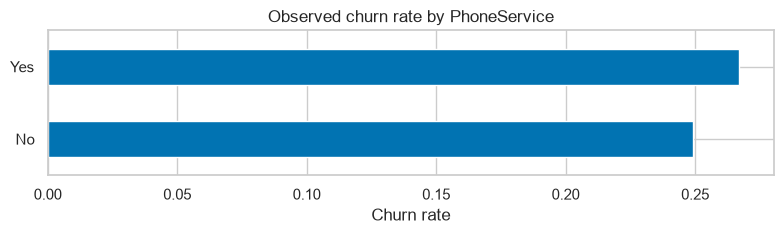

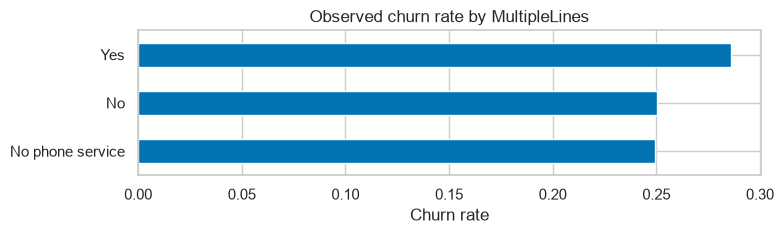

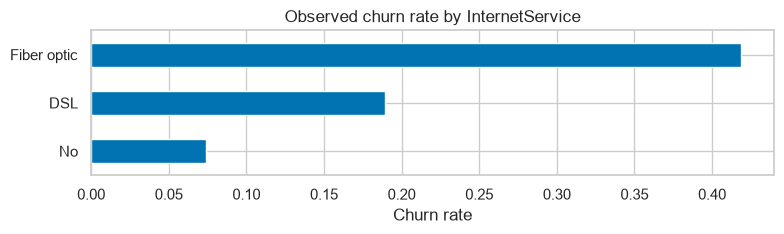

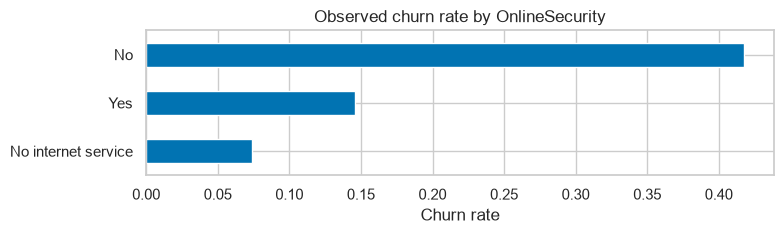

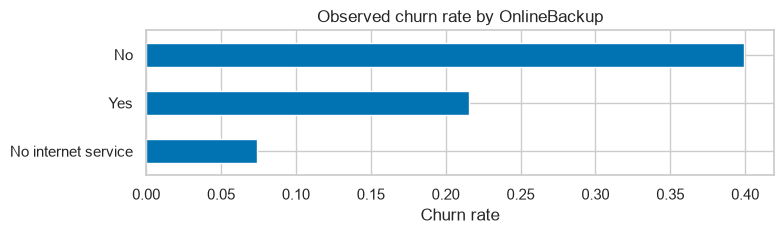

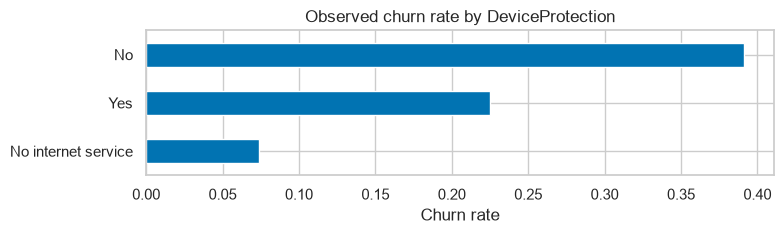

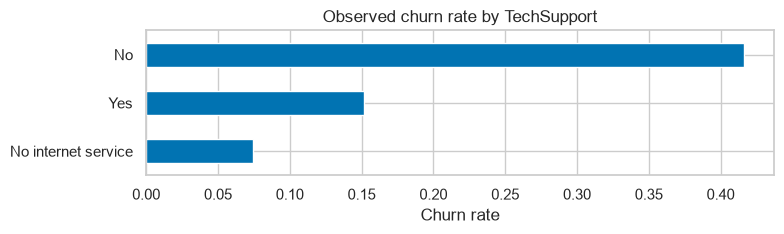

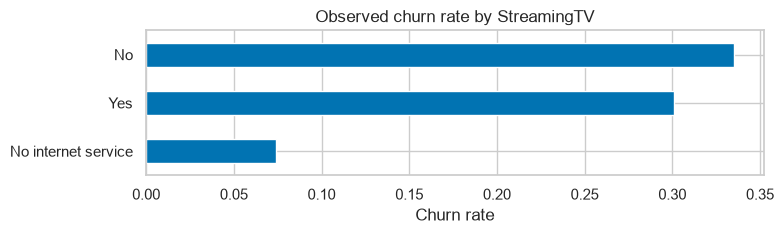

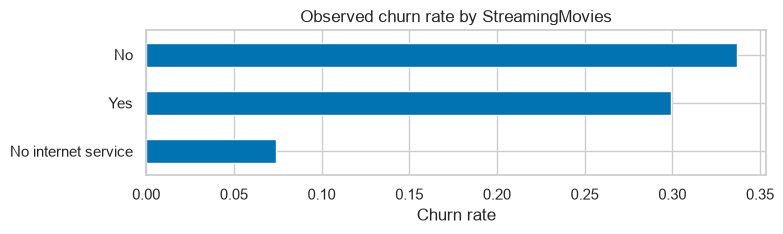

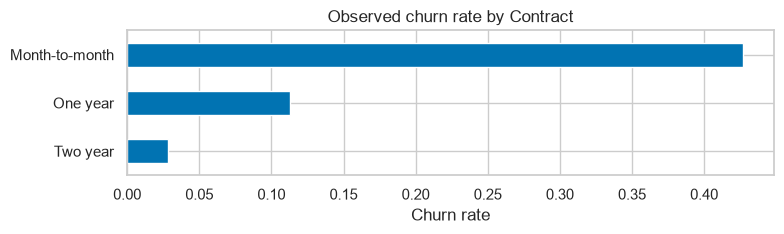

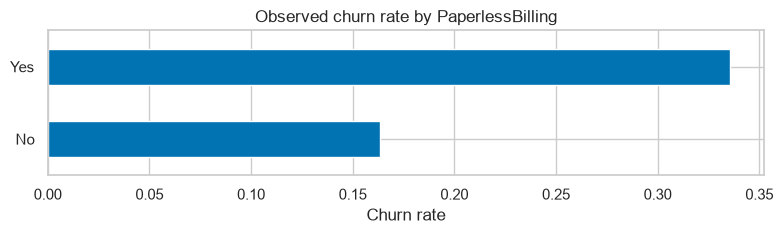

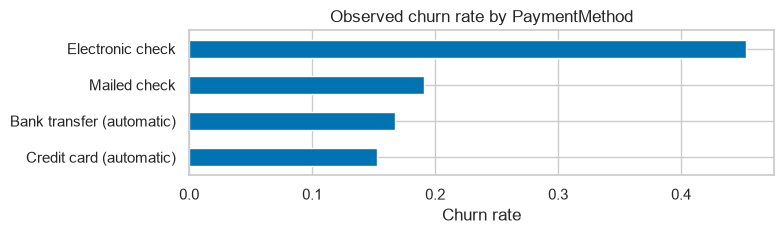

In [4]:
categorical = [c for c in df.select_dtypes(exclude='number').columns if c not in ['customerID', 'Churn']]
for column in categorical:
    rates = df.groupby(column, dropna=False)['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values(ascending=False)
    if rates.size <= 12:
        ax = rates.sort_values().plot(kind='barh', figsize=(8, max(2.5, .35 * len(rates))))
        ax.set(title=f'Observed churn rate by {column}', xlabel='Churn rate', ylabel='')
        plt.tight_layout(); plt.show()

# Save a compact quality summary for the report.
report_dir = ROOT / 'reports'; report_dir.mkdir(exist_ok=True)
quality_report(df).to_csv(report_dir / 'data_quality.csv')

## Initial readout
Record after running: (1) data shape and missingness, (2) strongest descriptive patterns, (3) at least one plausible confounder, and (4) what evidence notebook 02 should test. Do not interpret association as causation.

**Data caveat:** this is a historical benchmark sample, not a current operator's population. Its feature definitions and collection process may not match a real deployment.